In [9]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

# Place source_healthcare_patients_sample.csv in the same folder as this notebook.
source_path = Path("/content/healthcare_patients_sample (2).csv")
df_raw = pd.read_csv(source_path)

print("Shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes)


Shape: (10, 10)


,PatientID,Age,Gender,Diagnosis,PrimaryMedication,DosageMg,TreatmentDurationDays,Readmitted,BloodPressure,CholesterolLevel
0,PAT-201,42,Male,Hypertension,Amlodipine,10.0,90,No,138/88,210
1,PAT-202,58,Female,Type 2 Diabetes,Metformin,500.0,180,No,128/80,195
2,PAT-203,67,Male,Heart Disease,Atorvastatin,40.0,120,Yes,145/92,245
3,PAT-204,35,Female,Asthma,Albuterol,2.0,30,No,118/75,180
4,PAT-205,71,Female,Osteoarthritis,Ibuprofen,400.0,60,Yes,132/84,205


,0
PatientID,object
Age,int64
Gender,object
Diagnosis,object
PrimaryMedication,object
DosageMg,float64
TreatmentDurationDays,int64
Readmitted,object
BloodPressure,object
CholesterolLevel,int64


In [10]:
field_classification = {
    "PatientID": "Pseudonymous identifier; potentially linkable",
    "Age": "Demographic; quasi-identifier",
    "Gender": "Demographic; quasi-identifier",
    "Diagnosis": "Sensitive clinical information",
    "PrimaryMedication": "Sensitive clinical information",
    "DosageMg": "Sensitive clinical information",
    "TreatmentDurationDays": "Sensitive clinical information",
    "Readmitted": "Sensitive clinical outcome",
    "BloodPressure": "Sensitive clinical measurement",
    "CholesterolLevel": "Sensitive clinical measurement; unit not specified"
}
for field, classification in field_classification.items():
    print(f"{field}: {classification}")

print("\\nNo obvious direct identifiers such as name, phone, address, or DOB are present.")
print("This alone does NOT prove formal de-identification. Verify provenance and linkage risk.")


PatientID: Pseudonymous identifier; potentially linkable
Age: Demographic; quasi-identifier
Gender: Demographic; quasi-identifier
Diagnosis: Sensitive clinical information
PrimaryMedication: Sensitive clinical information
DosageMg: Sensitive clinical information
TreatmentDurationDays: Sensitive clinical information
Readmitted: Sensitive clinical outcome
BloodPressure: Sensitive clinical measurement
CholesterolLevel: Sensitive clinical measurement; unit not specified
\nNo obvious direct identifiers such as name, phone, address, or DOB are present.
This alone does NOT prove formal de-identification. Verify provenance and linkage risk.


In [11]:
#3.)Validate types, missingness, and duplicates

print("Data types:\\n", df_raw.dtypes)
print("\\nMissing values:\\n", df_raw.isna().sum())
print("\\nExact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate PatientID rows:", df_raw["PatientID"].duplicated(keep=False).sum())
print("Unique PatientIDs:", df_raw["PatientID"].nunique(dropna=True))


Data types:\n PatientID                 object
Age                        int64
Gender                    object
Diagnosis                 object
PrimaryMedication         object
DosageMg                 float64
TreatmentDurationDays      int64
Readmitted                object
BloodPressure             object
CholesterolLevel           int64
dtype: object
\nMissing values:\n PatientID                0
Age                      0
Gender                   0
Diagnosis                0
PrimaryMedication        0
DosageMg                 0
TreatmentDurationDays    0
Readmitted               0
BloodPressure            0
CholesterolLevel         0
dtype: int64
\nExact duplicate rows: 0
Duplicate PatientID rows: 0
Unique PatientIDs: 10


In [12]:
#4.)Apply conservative structural checks
exceptions = []

def flag(patient_id, field, issue, value):
    exceptions.append({
        "PatientID": patient_id, "Field": field,
        "Issue": issue, "ObservedValue": value,
        "Action": "Flag for authorized review; do not alter clinical value"
    })

for _, row in df_raw.iterrows():
    pid = row.get("PatientID")
    if pd.isna(pid) or str(pid).strip() == "":
        flag(pid, "PatientID", "Missing identifier", pid)

    # Broad data validation bounds only; not clinical reference ranges.
    if pd.notna(row.get("Age")) and not (0 <= float(row["Age"]) <= 120):
        flag(pid, "Age", "Outside broad data-validation bounds 0–120", row["Age"])

    if pd.notna(row.get("DosageMg")) and float(row["DosageMg"]) <= 0:
        flag(pid, "DosageMg", "Non-positive dosage", row["DosageMg"])

    if pd.notna(row.get("TreatmentDurationDays")) and float(row["TreatmentDurationDays"]) <= 0:
        flag(pid, "TreatmentDurationDays", "Non-positive duration", row["TreatmentDurationDays"])

    bp = str(row.get("BloodPressure", "")).strip()
    match = re.fullmatch(r"(\\d{2,3})/(\\d{2,3})", bp)
    if not match:
        flag(pid, "BloodPressure", "Invalid systolic/diastolic format", bp)
    else:
        systolic, diastolic = map(int, match.groups())
        if not (70 <= systolic <= 250 and 40 <= diastolic <= 150):
            flag(pid, "BloodPressure", "Outside broad screening bounds; verify source", bp)

    if row.get("Readmitted") not in ["Yes", "No"]:
        flag(pid, "Readmitted", "Expected Yes/No category", row.get("Readmitted"))

duplicate_ids = df_raw[df_raw["PatientID"].duplicated(keep=False)]
for _, row in duplicate_ids.iterrows():
    flag(row["PatientID"], "PatientID", "Duplicate patient identifier", row["PatientID"])

exception_log = pd.DataFrame(exceptions)
display(exception_log if not exception_log.empty else pd.DataFrame(
    [{"Result": "No exceptions detected by these structural rules"}]
))


,PatientID,Field,Issue,ObservedValue,Action
0,PAT-201,BloodPressure,Invalid systolic/diastolic format,138/88,Flag for authorized review; do not alter clini...
1,PAT-202,BloodPressure,Invalid systolic/diastolic format,128/80,Flag for authorized review; do not alter clini...
2,PAT-203,BloodPressure,Invalid systolic/diastolic format,145/92,Flag for authorized review; do not alter clini...
3,PAT-204,BloodPressure,Invalid systolic/diastolic format,118/75,Flag for authorized review; do not alter clini...
4,PAT-205,BloodPressure,Invalid systolic/diastolic format,132/84,Flag for authorized review; do not alter clini...
5,PAT-206,BloodPressure,Invalid systolic/diastolic format,125/82,Flag for authorized review; do not alter clini...
6,PAT-207,BloodPressure,Invalid systolic/diastolic format,135/86,Flag for authorized review; do not alter clini...
7,PAT-208,BloodPressure,Invalid systolic/diastolic format,115/72,Flag for authorized review; do not alter clini...
8,PAT-209,BloodPressure,Invalid systolic/diastolic format,150/95,Flag for authorized review; do not alter clini...
9,PAT-210,BloodPressure,Invalid systolic/diastolic format,122/78,Flag for authorized review; do not alter clini...


In [13]:
# Keep the original untouched. Only trim leading/trailing whitespace in text fields.
df_clean = df_raw.copy()
for col in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Do not impute missing clinical measurements or delete flagged rows automatically.
df_clean.to_csv("cleaned_healthcare_data.csv", index=False)
if exception_log.empty:
    exception_log = pd.DataFrame([{
        "PatientID": "", "Field": "",
        "Issue": "No exceptions detected by documented structural rules",
        "ObservedValue": "",
        "Action": "No values imputed and no rows deleted; provenance and clinical context still need review"
    }])
exception_log.to_csv("exception_log.csv", index=False)

print("Cleaned dataset saved. Rows retained:", len(df_clean))


Cleaned dataset saved. Rows retained: 10


In [15]:
df = df_clean
df

,PatientID,Age,Gender,Diagnosis,PrimaryMedication,DosageMg,TreatmentDurationDays,Readmitted,BloodPressure,CholesterolLevel
0,PAT-201,42,Male,Hypertension,Amlodipine,10.00,90,No,138/88,210
1,PAT-202,58,Female,Type 2 Diabetes,Metformin,500.00,180,No,128/80,195
2,PAT-203,67,Male,Heart Disease,Atorvastatin,40.00,120,Yes,145/92,245
3,PAT-204,35,Female,Asthma,Albuterol,2.00,30,No,118/75,180
4,PAT-205,71,Female,Osteoarthritis,Ibuprofen,400.00,60,Yes,132/84,205
5,PAT-206,50,Male,Type 2 Diabetes,Metformin,850.00,90,No,125/82,215
6,PAT-207,63,Female,Hypertension,Lisinopril,20.00,150,No,135/86,220
7,PAT-208,29,Male,Allergic Rhinitis,Cetirizine,10.00,14,No,115/72,175
8,PAT-209,76,Male,Heart Disease,Clopidogrel,75.00,365,Yes,150/95,260
9,PAT-210,48,Female,Hypothyroidism,Levothyroxine,0.05,180,No,122/78,190


In [16]:
# Show summary statistics for numerical columns
descriptive_stats = df.describe()
display(descriptive_stats)

,Age,DosageMg,TreatmentDurationDays,CholesterolLevel
count,10.000000,10.000000,10.000000,10.000000
mean,53.900000,190.705000,127.900000,209.500000
std,15.708809,293.758221,101.235095,27.126248
min,29.000000,0.050000,14.000000,175.000000
25%,43.500000,10.000000,67.500000,191.250000
50%,54.000000,30.000000,105.000000,207.500000
75%,66.000000,318.750000,172.500000,218.750000
max,76.000000,850.000000,365.000000,260.000000


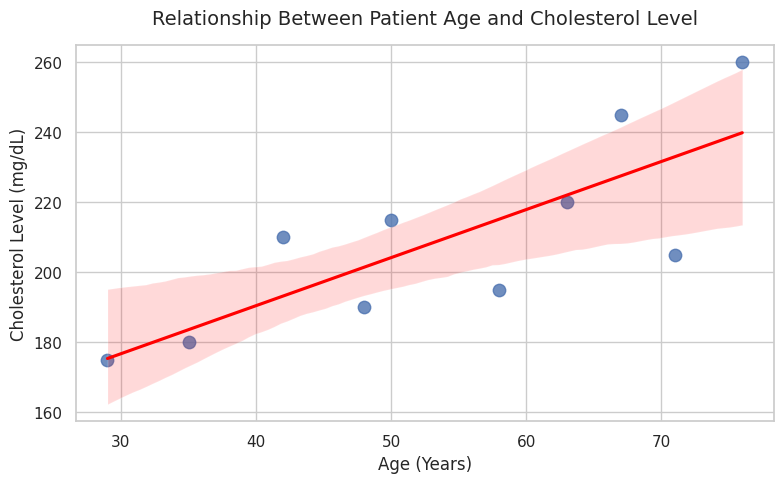

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Create the scatter plot with a linear regression line
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Age", y="CholesterolLevel", scatter_kws={"s": 80, "alpha": 0.8}, line_kws={"color": "red"})

# Customize titles and labels
plt.title("Relationship Between Patient Age and Cholesterol Level", fontsize=14, pad=15)
plt.xlabel("Age (Years)", fontsize=12)
plt.ylabel("Cholesterol Level (mg/dL)", fontsize=12)

# Display plot
plt.tight_layout()
plt.show()

/tmp/ipykernel_1983/2592363567.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Gender", y="CholesterolLevel", palette="pastel")


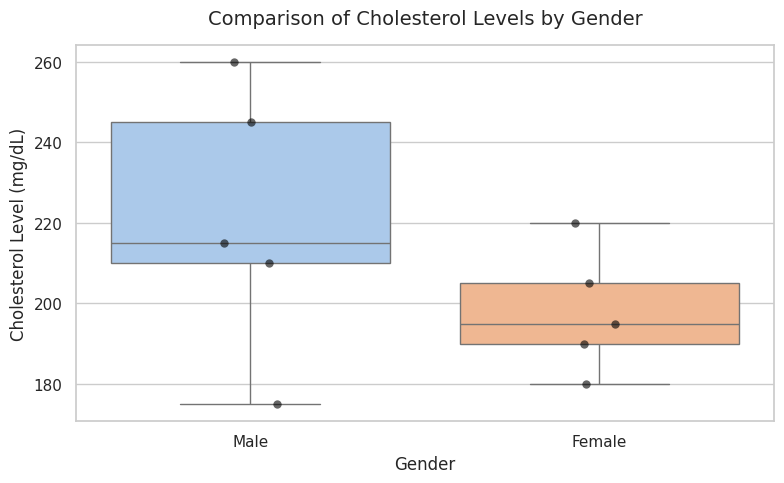

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set theme style
sns.set_theme(style="whitegrid")

# Create the boxplot comparing CholesterolLevel by Gender
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Gender", y="CholesterolLevel", palette="pastel")

# Add individual data points to show distribution density
sns.stripplot(data=df, x="Gender", y="CholesterolLevel", color="black", size=6, alpha=0.6, jitter=0.1)

# Customize titles and labels
plt.title("Comparison of Cholesterol Levels by Gender", fontsize=14, pad=15)
plt.xlabel("Gender", fontsize=12)
plt.ylabel("Cholesterol Level (mg/dL)", fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

In [19]:
# Calculate average CholesterolLevel grouped by Diagnosis
avg_cholesterol_by_diagnosis = df.groupby('Diagnosis')['CholesterolLevel'].mean().reset_index()

# Sort by average cholesterol level descending
avg_cholesterol_by_diagnosis = avg_cholesterol_by_diagnosis.sort_values(by='CholesterolLevel', ascending=False)

display(avg_cholesterol_by_diagnosis)

,Diagnosis,CholesterolLevel
2,Heart Disease,252.5
3,Hypertension,215.0
5,Osteoarthritis,205.0
6,Type 2 Diabetes,205.0
4,Hypothyroidism,190.0
1,Asthma,180.0
0,Allergic Rhinitis,175.0


### Identifying Potential Outliers in CholesterolLevel
We will use the **Interquartile Range (IQR) method** to identify statistically significant outliers. Outliers are typically defined as values falling below $Q1 - 1.5 \times IQR$ or above $Q3 + 1.5 \times IQR$.

In [20]:
# Calculate IQR for CholesterolLevel
Q1 = df['CholesterolLevel'].quantile(0.25)
Q3 = df['CholesterolLevel'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify IQR outliers
iqr_outliers = df[(df['CholesterolLevel'] < lower_bound) | (df['CholesterolLevel'] > upper_bound)]

print(f"Cholesterol Level Bounds: Lower Bound = {lower_bound:.2f}, Upper Bound = {upper_bound:.2f}")
print(f"Number of IQR outliers detected: {len(iqr_outliers)}")
display(iqr_outliers)

Cholesterol Level Bounds: Lower Bound = 150.00, Upper Bound = 260.00
Number of IQR outliers detected: 0


,PatientID,Age,Gender,Diagnosis,PrimaryMedication,DosageMg,TreatmentDurationDays,Readmitted,BloodPressure,CholesterolLevel


Let's also check for extreme values that are more than 1.5 standard deviations away from the mean, given our relatively small sample size.

In [21]:
# Identify values beyond 1.5 standard deviations from the mean
mean_chol = df['CholesterolLevel'].mean()
std_chol = df['CholesterolLevel'].std()
threshold_std = 1.5

sd_outliers = df[np.abs(df['CholesterolLevel'] - mean_chol) > (threshold_std * std_chol)]
print(f"Mean Cholesterol: {mean_chol:.2f}, Std Dev: {std_chol:.2f}")
print(f"Records more than {threshold_std} standard deviations away from mean:")
display(sd_outliers)

Mean Cholesterol: 209.50, Std Dev: 27.13
Records more than 1.5 standard deviations away from mean:


,PatientID,Age,Gender,Diagnosis,PrimaryMedication,DosageMg,TreatmentDurationDays,Readmitted,BloodPressure,CholesterolLevel
8,PAT-209,76,Male,Heart Disease,Clopidogrel,75.0,365,Yes,150/95,260


### Relationship Between Treatment Duration and Dosage
Let's visualize how the duration of treatment correlates with the dosage prescribed to the patients.

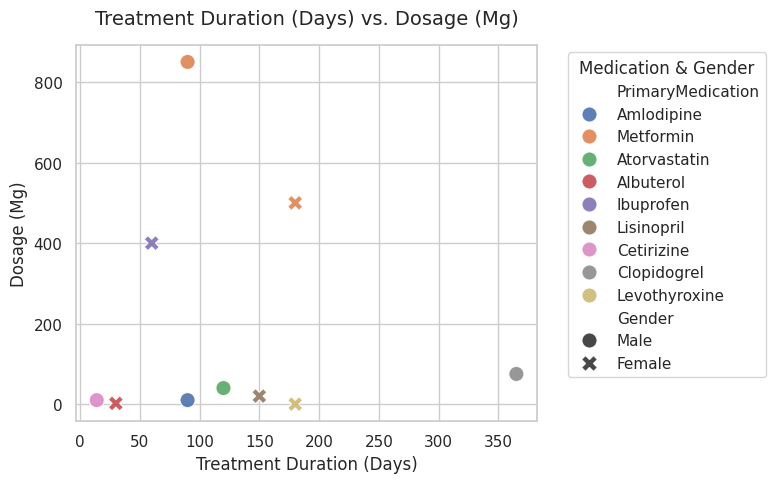

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Create a scatter plot representing TreatmentDurationDays vs DosageMg
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="TreatmentDurationDays",
    y="DosageMg",
    hue="PrimaryMedication",
    style="Gender",
    s=120,
    alpha=0.9
)

# Customize titles and labels
plt.title("Treatment Duration (Days) vs. Dosage (Mg)", fontsize=14, pad=15)
plt.xlabel("Treatment Duration (Days)", fontsize=12)
plt.ylabel("Dosage (Mg)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Medication & Gender")

plt.tight_layout()
plt.show()